# Charts

Two figures, both read from `data/gold/` only. Neither recomputes anything.

1. The publication timeline — what each series covered, when it was published, and the empty
   stretch that follows.
2. The local authority distribution at 31 March 2024, against the England figure and the 80% target.

Colour does no work separating series: each band carries its own row label, so one hue is used
throughout and emphasis comes from ink weight and shading instead.

## 1. Setup

In [3]:
from pathlib import Path

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

BASE_DIR   = Path.home() / "projects" / "nhs-cervical-screening-pipeline"
GOLD_DIR   = BASE_DIR / "data" / "gold"
CHARTS_DIR = BASE_DIR / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

la       = pd.read_parquet(GOLD_DIR / "la_coverage_2024_03_31.parquet")
timeline = pd.read_parquet(GOLD_DIR / "coverage_timeline.parquet")
register = pd.read_parquet(GOLD_DIR / "publication_register.parquet")
facts    = pd.read_csv(GOLD_DIR / "facts.csv").set_index("name").value

# Categorical slot 1 plus chart chrome, validated for contrast on the light surface.
SERIES  = "#2a78d6"
SURFACE = "#fcfcfb"
INK     = "#0b0b0b"
INK_2   = "#52514e"
MUTED   = "#898781"
GRID    = "#e1e0d9"
AXIS    = "#c3c2b7"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 150, "savefig.dpi": 150, "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})

ANNOUNCEMENT = pd.Timestamp("2026-08-25")

def save(fig, name):
    for ext in ("png", "svg"):
        fig.savefig(CHARTS_DIR / f"{name}.{ext}")
    print(f"charts/{name}.png  charts/{name}.svg")

print(f"la {len(la)} | timeline {len(timeline)} | register {len(register)} | facts {len(facts)}")

la 151 | timeline 29 | register 28 | facts 47


## 2. The publication timeline

Three bands. An open marker is a period the series reported on; a filled marker is a date something
was published. Where both are known they are joined, so the connector's length is the publication lag.

The quarterly dashboard band is deliberately incomplete. Its thirteen quarters are known, but the
archive preserves only the final publication date, not when each quarter first appeared. That gap in
the record is part of the story, so the chart leaves it rather than inventing dates.

charts/publication_timeline.png  charts/publication_timeline.svg


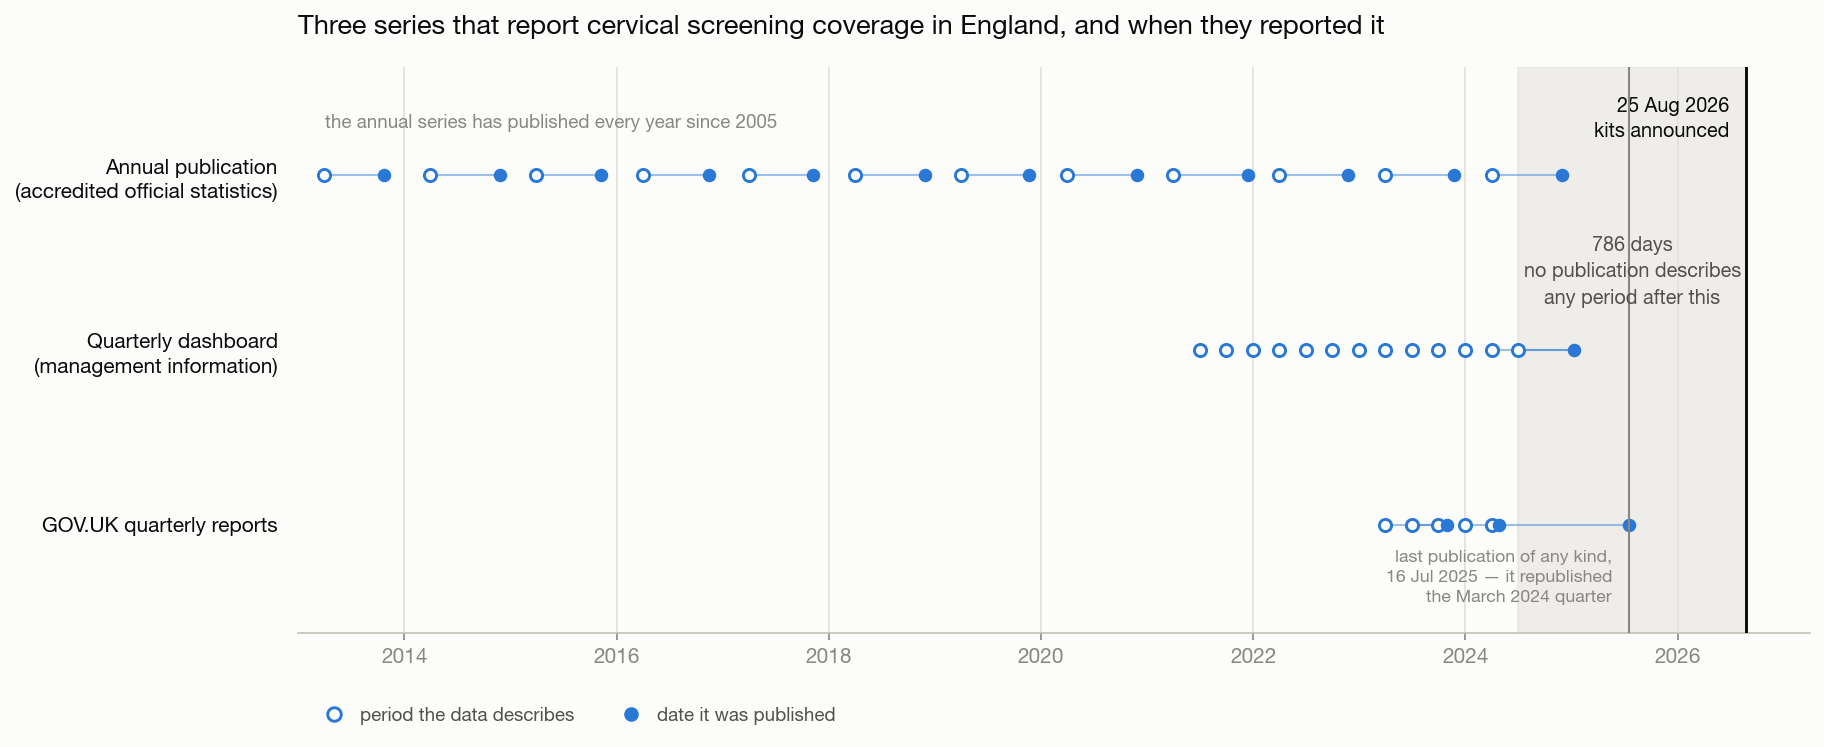

In [5]:
BANDS = [
    ("annual",          "Annual publication\n(accredited official statistics)"),
    ("mi_quarterly",    "Quarterly dashboard\n(management information)"),
    ("govuk_quarterly", "GOV.UK quarterly reports"),
]

fig, ax = plt.subplots(figsize=(13, 4.9))

for i, (series, label) in enumerate(BANDS):
    y = len(BANDS) - 1 - i

    # "not downloaded" rows are the annual series history parsed from the publisher's own page.
    # Those are publications too, so only genuinely rejected sources are dropped here.
    pubs = register[(register.series == series) & (register.status != "rejected")]

    periods = pd.to_datetime(pd.concat([
        timeline[timeline.series == series].period_end,
        pubs.reference_period_end]).dropna().unique())
    pub_dates = pd.to_datetime(pubs.publication_date.dropna().unique())

    for r in pubs.dropna(subset=["reference_period_end", "publication_date"]).itertuples():
        ax.plot([r.reference_period_end, r.publication_date], [y, y],
                color=SERIES, linewidth=1.0, alpha=0.45, solid_capstyle="round", zorder=2)

    ax.scatter(periods, [y] * len(periods), s=34, facecolors=SURFACE,
               edgecolors=SERIES, linewidths=1.4, zorder=3)
    ax.scatter(pub_dates, [y] * len(pub_dates), s=30, color=SERIES, zorder=4)

# The honest gap is not the pause between releases but the stretch no publication describes:
# nothing published since covers any period after the last observation.
last_period = pd.to_datetime(timeline.period_end).max()
last_event = pd.to_datetime(register[register.status != "rejected"].publication_date).max()

ax.axvspan(last_period, ANNOUNCEMENT, color=GRID, alpha=0.5, zorder=0)
ax.axvline(ANNOUNCEMENT, color=INK, linewidth=1.4, zorder=5)
ax.axvline(last_event, color=MUTED, linewidth=1.0, zorder=5)

gap_days = (ANNOUNCEMENT - last_period).days
ax.annotate(f"{gap_days} days\nno publication describes\nany period after this",
            xy=(last_period + (ANNOUNCEMENT - last_period) / 2, 1.45),
            ha="center", va="center", fontsize=9.5, color=INK_2, linespacing=1.5, zorder=6)
ax.annotate("last publication of any kind,\n16 Jul 2025 — it republished\nthe March 2024 quarter",
            xy=(last_event, -0.30), xytext=(-8, 0), textcoords="offset points",
            ha="right", va="center", fontsize=8.5, color=MUTED, linespacing=1.4)
ax.annotate("25 Aug 2026\nkits announced", xy=(ANNOUNCEMENT, 2.45),
            xytext=(-8, 0), textcoords="offset points",
            ha="right", va="top", fontsize=9.5, color=INK, linespacing=1.4)
ax.annotate("the annual series has published every year since 2005",
            xy=(pd.Timestamp("2013-04-01"), 2.30), ha="left", va="center",
            fontsize=9, color=MUTED, style="italic")

# band names as row labels, so identity never rests on colour
ax.set_yticks([2, 1, 0])
ax.set_yticklabels([label for _, label in BANDS], fontsize=10, color=INK, linespacing=1.35)
ax.tick_params(axis="y", length=0, pad=10)

ax.set_ylim(-0.62, 2.62)
ax.set_xlim(pd.Timestamp("2013-01-01"), pd.Timestamp("2027-03-31"))
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="none", markerfacecolor=SURFACE,
           markeredgecolor=SERIES, markeredgewidth=1.4, markersize=6.5,
           label="period the data describes"),
    Line2D([], [], marker="o", linestyle="none", color=SERIES, markersize=6.0,
           label="date it was published"),
], loc="upper left", frameon=False, fontsize=9, handletextpad=0.4,
   labelcolor=INK_2, ncol=2, bbox_to_anchor=(0.0, -0.10))

ax.set_title("Three series that report cervical screening coverage in England, "
             "and when they reported it", fontsize=13, color=INK, loc="left", pad=16)

save(fig, "publication_timeline")
plt.show()

## 3. The local authority distribution

151 authorities at 31 March 2024. One series, one hue, no legend needed — the title names it.

Two reference lines carry the point: the England figure the programme is aimed at, and the target it
is measured against. The shaded band between the best authority and the target is the space nobody
occupies.

charts/la_coverage_distribution.png  charts/la_coverage_distribution.svg


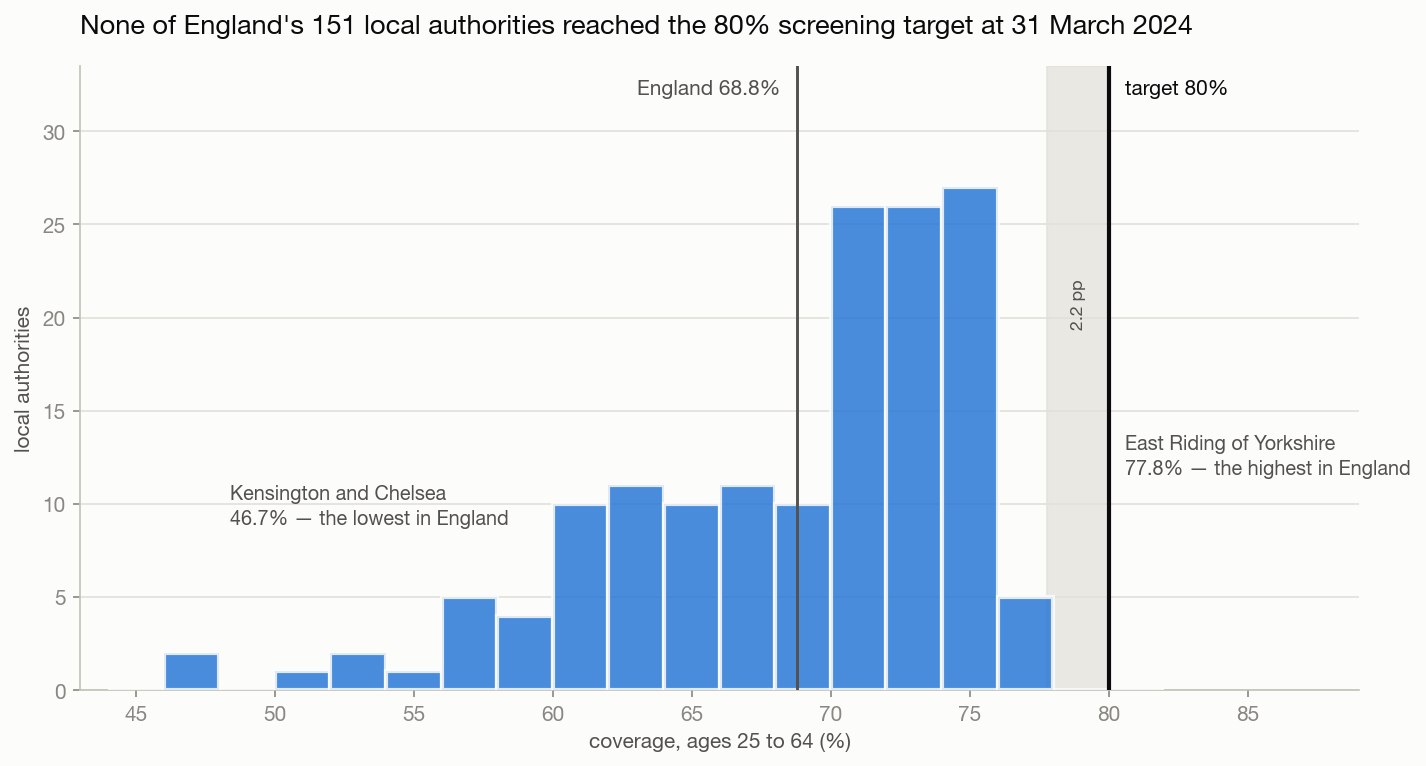

In [7]:
england = float(facts.headline_coverage_pct)
target = float(facts.target_pct)

fig, ax = plt.subplots(figsize=(11, 5.4))

counts, edges, _ = ax.hist(la.coverage_pct, bins=range(44, 84, 2), color=SERIES, alpha=0.85,
                           edgecolor=SURFACE, linewidth=2.0, zorder=3)

ax.axvspan(la.coverage_pct.max(), target, color=GRID, alpha=0.7, zorder=1)
ax.axvline(england, color=INK_2, linewidth=1.4, zorder=4)
ax.axvline(target, color=INK, linewidth=2.0, zorder=4)

headroom = counts.max() * 1.24
ax.set_ylim(0, headroom)

ax.annotate(f"England {england:.1f}%", xy=(england, headroom * 0.98), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="top", fontsize=10, color=INK_2)
ax.annotate(f"target {target:.0f}%", xy=(target, headroom * 0.98), xytext=(8, 0),
            textcoords="offset points", ha="left", va="top", fontsize=10, color=INK)

# Extremes labelled in clear space, reading rightwards, so nothing crosses a bar or a rule.
hi, lo = la.iloc[-1], la.iloc[0]
lo_idx = max((edges <= lo.coverage_pct).sum() - 1, 0)

ax.annotate(f"{lo.org_name}\n{lo.coverage_pct:.1f}% — the lowest in England",
            xy=(edges[lo_idx + 1] + 0.4, headroom * 0.26),
            ha="left", va="bottom", fontsize=9.5, color=INK_2, linespacing=1.4)

# past the target rule, where the only thing to collide with is empty axis
ax.annotate(f"{hi.org_name}\n{hi.coverage_pct:.1f}% — the highest in England",
            xy=(target + 0.6, headroom * 0.34),
            ha="left", va="bottom", fontsize=9.5, color=INK_2, linespacing=1.4)

# INK_2 rather than muted: this label sits on the shaded band, so it needs the contrast
ax.annotate(f"{target - hi.coverage_pct:.1f} pp", rotation=90,
            xy=((hi.coverage_pct + target) / 2, headroom * 0.62),
            ha="center", va="center", fontsize=8.5, color=INK_2)

ax.set_xlabel("coverage, ages 25 to 64 (%)", fontsize=10)
ax.set_ylabel("local authorities", fontsize=10)
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.set_xlim(43, 89)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

ax.set_title(f"None of England's {len(la)} local authorities reached the 80% screening target "
             f"at 31 March 2024", fontsize=13, color=INK, loc="left", pad=16)

save(fig, "la_coverage_distribution")
plt.show()

## 4. The table view

Both figures need a non-visual equivalent — for accessibility, and because a reader who wants the
numbers should not have to read them off a chart.

In [9]:
dist = (la.assign(band=pd.cut(la.coverage_pct, bins=range(44, 84, 2)))
          .groupby("band", observed=True)
          .agg(authorities=("org_name", "size")).reset_index())
dist["band"] = (dist.band.astype(str)
                .str.replace(r"[\(\]]", "", regex=True).str.replace(",", " to "))
dist.to_csv(CHARTS_DIR / "la_coverage_distribution_table.csv", index=False)

tl = (register[register.status != "rejected"]
      [["series", "source_id", "reference_period_end", "publication_date", "lag_days"]]
      .sort_values("publication_date"))
tl.to_csv(CHARTS_DIR / "publication_timeline_table.csv", index=False)

print(dist.to_string(index=False))
print()
print(f"charts/la_coverage_distribution_table.csv  ({len(dist)} bands)")
print(f"charts/publication_timeline_table.csv      ({len(tl)} publications)")

     band  authorities
46 to  48            2
50 to  52            1
52 to  54            2
54 to  56            1
56 to  58            5
58 to  60            4
60 to  62           10
62 to  64           11
64 to  66           10
66 to  68           11
68 to  70           10
70 to  72           26
72 to  74           26
74 to  76           27
76 to  78            5

charts/la_coverage_distribution_table.csv  (15 bands)
charts/publication_timeline_table.csv      (27 publications)
